# Paracetamol: torsion distributions written in one labelling

The symmetry-first clustering ([previous notebook](clustering.ipynb)) found two clusters. This page
asks a different question of the same fit: **how should a torsion histogram be drawn when the same
configuration can be written in more than one atom labelling?** The ring flip renames C5 as C10, so
a frame can appear as `aryl = -16` degrees or as `aryl = 164` degrees, and a histogram of the stored
column shows both. Each frame is written in the labelling **nearest one reference frame**, the
density peak of the largest cluster, and every operation acts on the whole row of angles at once.

The explanation, the definitions and the limits are in
[Methods: analysis, symmetry-aware clustering and the torsion representation](../../../openmm_methods/analysis/clustering-and-symmetry.md);
this page shows what the rule gives on paracetamol and nothing else.

!!! note "Relabelling moves no atom and drops no frame"
    Every frame is kept, once. The operation used is returned per frame.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1] / "_analysis"))   # docs/tutorial/_analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mdtraj as md
from rdkit import Chem
import tutorial_data as td
import md_tools
from md_tools.analysis import (TorsionDefinitions, t_hdbscan, verify_atom_mapping, group_name)

print("tutorial runs:", "found" if td.runs_root().is_dir() else "MISSING")
print("md-tools", md_tools.__version__)

tutorial runs: found
md-tools 0.6.5.1


## 1. The fit this page starts from

The same input as the clustering notebook: the 1 us cMD run at stride 25 (4000 frames), the three
selected torsions, and the default `t_hdbscan` call with the symmetry-aware distance, a mass floor of
1 % of the fitted frames (`min_cluster_size` 40) and `min_samples` 40.

In [2]:
mol = Chem.SDMolSupplier(str(td.run_dir("PARA-REST2") / "build/TYL.sdf"), removeHs=False)[0]
TORSIONS = {"omega": (0, 1, 3, 4), "aryl": (1, 3, 4, 5), "phenol": (6, 7, 8, 17)}
definitions = TorsionDefinitions(quads=tuple(TORSIONS.values()), names=tuple(TORSIONS),
                                 indexing="zero-based", units="radian")
cmd = td.solute("PARA-1us", stride=25)
tors = md.compute_dihedrals(cmd, list(TORSIONS.values()))
mapping, why = verify_atom_mapping(mol, [(b[0].index, b[1].index) for b in cmd.topology.bonds],
                                   [a.element.symbol for a in cmd.topology.atoms])
fit = t_hdbscan(tors, molecule=mol, torsion_definitions=definitions, coordinates=cmd,
                atom_mapping=mapping).fit()
desc = fit.descriptor_
s = fit.summary()
print(f"{s['n_fit_frames']} frames, {s['n_clusters']} clusters, min_cluster_size "
      f"{s['settings']['min_cluster_size']}, min_samples {s['settings']['min_samples']}")
pd.DataFrame([{"cluster": group_name(c), "frames": int((fit.labels_ == c).sum()),
               "mass": round(float(fit.cluster_mass_[c]), 4)} for c in range(fit.n_clusters_)]
             + [{"cluster": "density noise", "frames": int((fit.labels_ == -2).sum()),
                 "mass": round(float(fit.noise_mass_), 4)}])

4000 frames, 2 clusters, min_cluster_size 40, min_samples 40


,cluster,frames,mass
0,A,2056,0.5140
1,B,1935,0.4838
2,density noise,9,0.0022


## 2. The columns and their weights

A torsion's image under the ring flip is a column of its own, computed from coordinates. Each orbit
carries the weight of the torsions selected in it, split equally among its columns, so the ring
orientation counts once.

In [3]:
pd.DataFrame([{"column": n, "atoms": "-".join(map(str, q)), "weight": w,
               "origin": "selected" if o["kind"] == "selected" else f"image of {o['image_of']}"}
              for n, q, w, o in zip(desc.names, desc.quads, desc.column_weights, desc.origin)])

,column,atoms,weight,origin
0,omega,0-1-3-4,1.0,selected
1,aryl,1-3-4-5,0.5,selected
2,phenol,6-7-8-17,0.5,selected
3,aryl@1-3-4-10,1-3-4-10,0.5,image of aryl
4,phenol@9-7-8-17,9-7-8-17,0.5,image of phenol


## 3. The reference: the density peak of the largest cluster

The reference is an actual frame, the member of cluster A with the smallest core distance (the
distance to its 40th nearest fitted frame under the symmetry-aware distance).

In [4]:
ref = fit.density_peak(0)
print(f"reference: frame {ref}, cluster {group_name(int(fit.labels_[ref]))}, "
      f"core distance {fit.core_distance_[ref]:.3f}")
pd.DataFrame(np.rad2deg(fit.closed_theta_[[ref]]), columns=desc.names, index=["reference"]).round(1)

reference: frame 3899, cluster A, core distance 0.153


,omega,aryl,phenol,aryl@1-3-4-10,phenol@9-7-8-17
reference,173.4,-16.0,8.0,167.0,-171.7


## 4. Every frame in the labelling nearest the reference

Each cluster's frames are aligned to the cluster's own density peak, and that peak is written in the
labelling nearest the reference above. The `margin` is the distance of a frame's second-best
labelling minus its best; a small margin means the frame sits near the wall between two labellings
and the choice is arbitrary.

In [5]:
al = fit.align_all(per_cluster=True)
rows = []
for c in range(fit.n_clusters_):
    m = fit.labels_ == c
    rows.append({"cluster": group_name(c), "density peak": int(al["cluster_references"][c]),
                 "frames relabelled": round(float((al["operations"][m] != 0).mean()), 3),
                 "mean distance, no relabelling": round(float(al["distance_identity"][m].mean()), 3),
                 "mean distance, nearest": round(float(al["distance"][m].mean()), 3),
                 "frames with margin < 0.1": round(float((al["margin"][m] < 0.1).mean()), 3)})
pd.DataFrame(rows)

,cluster,density peak,frames relabelled,"mean distance, no relabelling","mean distance, nearest",frames with margin < 0.1
0,A,3899,0.547,1.795,0.623,0.0
1,B,3271,0.434,1.584,0.689,0.0


## 5. The marginals, as stored and written in one labelling

Top: as stored. Bottom: every frame in the labelling nearest the reference. The five columns are the
three selected torsions and the two ring-flip images that were added to close the descriptor.

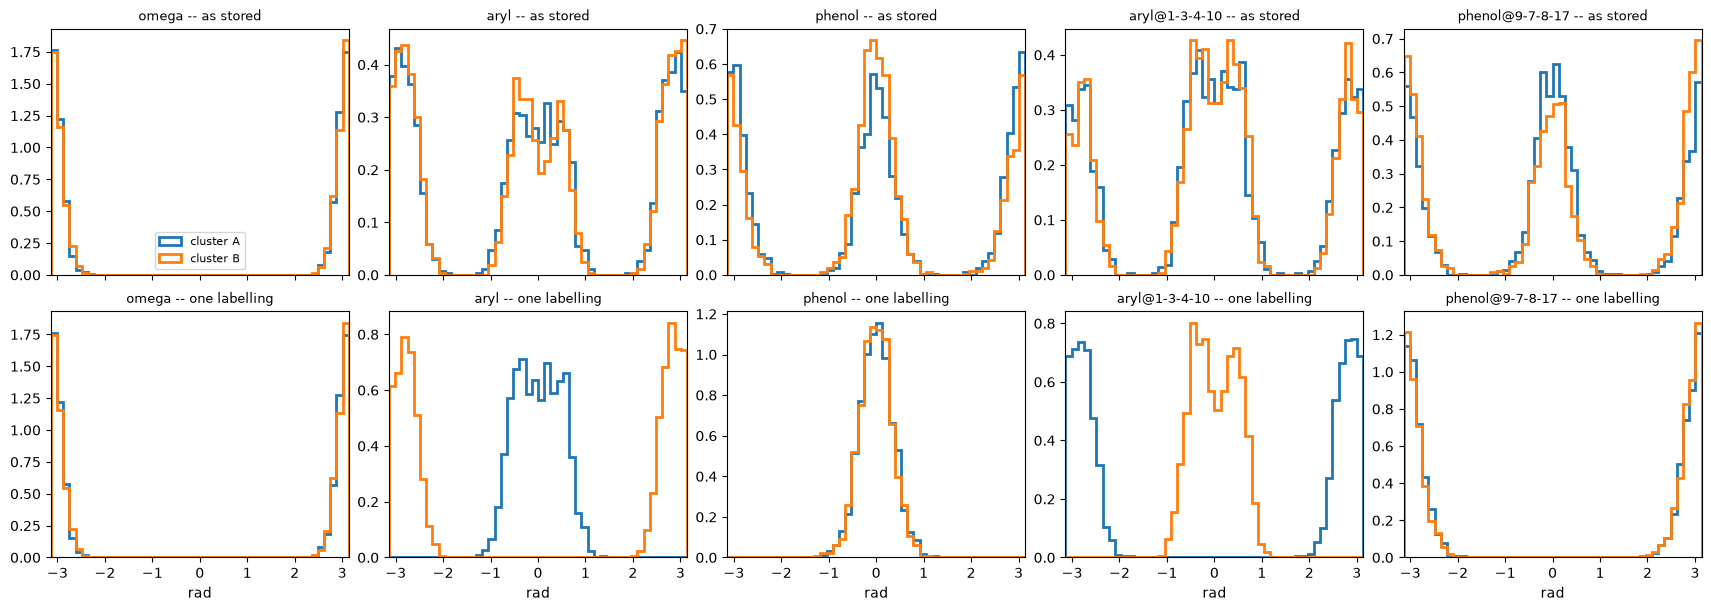

In [6]:
edges = np.linspace(-np.pi, np.pi, 49)
palette = plt.get_cmap("tab10")
fig, axes = plt.subplots(2, 5, figsize=(17, 6), layout="constrained", sharex=True)
for r, (title, theta) in enumerate((("as stored", fit.closed_theta_), ("one labelling", al["angles"]))):
    for col, name in enumerate(desc.names):
        for k in range(fit.n_clusters_):
            axes[r, col].hist(theta[fit.labels_ == k, col], bins=edges, density=True, histtype="step",
                              lw=2.0, color=palette(k), label=f"cluster {group_name(k)}")
        axes[r, col].set_xlim(-np.pi, np.pi)
        axes[r, col].set_title(f"{name} -- {title}", fontsize=9)
for col in range(5):
    axes[1, col].set_xlabel("rad")
axes[0, 0].legend(fontsize=8)
plt.show()

## 6. The ring pair

`aryl` (1-3-4-5) and its image `aryl@1-3-4-10` are one rotation seen through two atoms: the second is
the first plus half a turn plus a small ring distortion `delta`. The flip swaps the two columns, so it
maps `delta` to `-delta`.

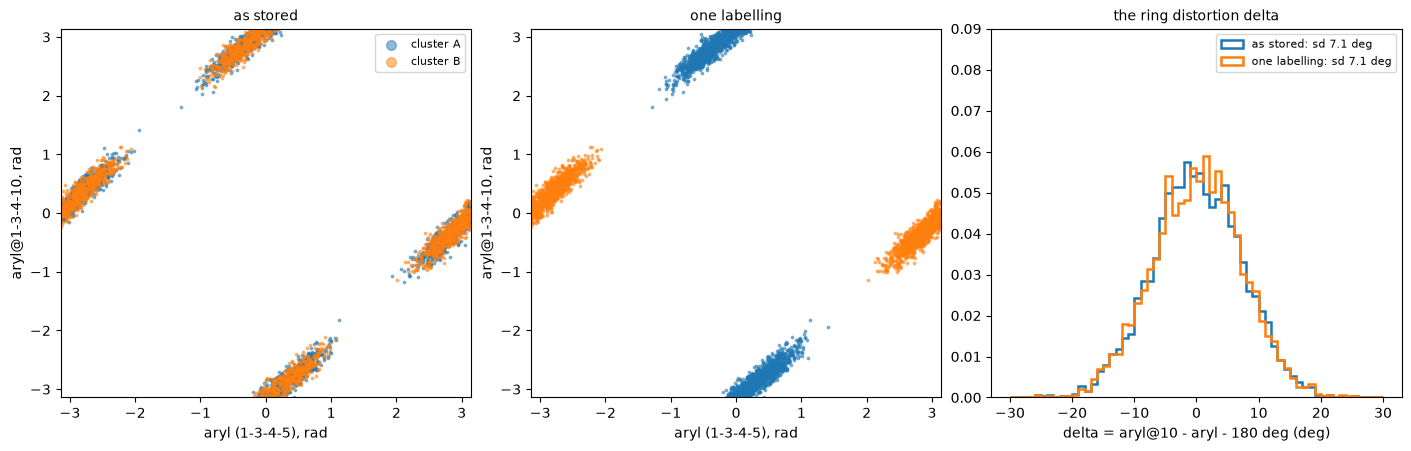

In [7]:
a, b = desc.names.index("aryl"), desc.names.index("aryl@1-3-4-10")
wrap = lambda x: np.angle(np.exp(1j * x))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), layout="constrained")
panels = [("as stored", fit.closed_theta_), ("one labelling", al["angles"])]
for ax, (title, th) in zip(axes[:2], panels):
    for k in range(fit.n_clusters_):
        sel = fit.labels_ == k
        ax.scatter(th[sel, a], th[sel, b], s=3, alpha=0.5, color=palette(k), label=f"cluster {group_name(k)}")
    ax.set_xlim(-np.pi, np.pi); ax.set_ylim(-np.pi, np.pi)
    ax.set_xlabel("aryl (1-3-4-5), rad"); ax.set_ylabel("aryl@1-3-4-10, rad"); ax.set_title(title, fontsize=10)
axes[0].legend(markerscale=4, fontsize=8)
bins = np.linspace(-30, 30, 61)
for title, th in panels:
    delta = np.rad2deg(wrap(th[:, b] - th[:, a] - np.pi))
    axes[2].hist(delta, bins=bins, density=True, histtype="step", lw=1.8,
                 label=f"{title}: sd {delta.std():.1f} deg")
axes[2].set_xlabel("delta = aryl@10 - aryl - 180 deg (deg)"); axes[2].set_ylim(0, 0.09)
axes[2].legend(fontsize=8); axes[2].set_title("the ring distortion delta", fontsize=10)
plt.show()

The partner is not a second free torsion: it stays on the line `aryl + 180 deg`. What is left is
`delta`, the ring distortion, and on this trajectory it is symmetric about zero in every cluster
(mean 0.1 deg, standard deviation 7.1 deg, as stored and relabelled alike), so the relabelling leaves
its histogram where it was.

## 7. Torsion table, in the one labelling

Circular mean and circular standard deviation of each selected torsion, per cluster.

In [8]:
def circ(values):
    R = np.hypot(np.sin(values).mean(), np.cos(values).mean())
    return np.rad2deg(np.arctan2(np.sin(values).mean(), np.cos(values).mean())), np.rad2deg(np.sqrt(-2.0 * np.log(max(R, 1e-12))))

rows = []
for c in range(fit.n_clusters_):
    row = {"cluster": group_name(c)}
    for j, n in enumerate(definitions.names):
        mean, sd = circ(al["selected"][fit.labels_ == c, j])
        row[f"{n}_avg"], row[f"{n}_std"] = round(mean, 2), round(sd, 2)
    row["mass"] = round(float(fit.cluster_mass_[c]), 4)
    rows.append(row)
pd.DataFrame(rows)

,cluster,omega_avg,omega_std,aryl_avg,aryl_std,phenol_avg,phenol_std,mass
0,A,179.87,12.31,0.03,27.76,-0.00,19.88,0.5140
1,B,179.95,12.67,-179.53,24.46,-0.77,19.35,0.4838


## 8. Paracetamol in a crystal: one structure, two assignments

Two entries of the Protein Data Bank hold paracetamol as the ligand `TYL`: **4YJI** (1.73 A, a
bacterial aryl acylamidase) and **4A9K** (1.81 A, the CREBBP bromodomain). Their ligand coordinates
(`data/4YJI_TYL.sdf`, `data/4A9K_TYL.sdf`) come from the PDB model server (`models.rcsb.org`, component
`TYL`). These are paracetamol **bound to a protein**, not the crystal of the drug itself, and a
crystal structure has no hydrogens.

Matching a crystal ligand onto the simulated molecule gives one atom assignment per graph match. The
ring can be assigned either way round, and the **same structure** is then two different rows of
torsions: `aryl` is one value through C5 and half a turn away through C10.

In [9]:
from md_tools.analysis import reference_assignments

CRYSTALS = {"4YJI": "data/4YJI_TYL.sdf", "4A9K": "data/4A9K_TYL.sdf"}
rows = {pdb: reference_assignments(path, mol, desc.quads) for pdb, path in CRYSTALS.items()}
table = []
for pdb, r in rows.items():
    for k, row in enumerate(r):
        table.append({"crystal": pdb, "assignment": k,
                      **{n: (round(float(np.rad2deg(v)), 1) if np.isfinite(v) else "n/a (through H)")
                         for n, v in zip(desc.names, row)}})
pd.DataFrame(table)

[15:26:51] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[15:26:51] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.


,crystal,assignment,omega,aryl,phenol,aryl@1-3-4-10,phenol@9-7-8-17
0,4YJI,0,-179.7,53.6,n/a (through H),-127.8,n/a (through H)
1,4YJI,1,-179.7,-127.8,n/a (through H),53.6,n/a (through H)
2,4A9K,0,-179.4,-173.1,n/a (through H),5.4,n/a (through H)
3,4A9K,1,-179.4,5.4,n/a (through H),-173.1,n/a (through H)


Two assignments for each crystal, and in the second `aryl` is the first plus about half a turn.
The `phenol` columns go through a hydrogen and cannot be measured. Drawing both as lines puts two
lines on one panel for one structure, as is right for frames **as stored**, which can be in either
labelling. For the clusters, which are in one labelling, the crystal is written in the labelling
**nearest the reference of that row**, so one line. `fit.assign_reference` does that for every cluster
and says which cluster the crystal resembles.

In [10]:
assigned = {pdb: fit.assign_reference(r) for pdb, r in rows.items()}
summary_rows = []
for pdb, out in assigned.items():
    for c, v in out["clusters"].items():
        summary_rows.append({"crystal": pdb, "cluster": group_name(c), "assignment chosen": v["assignment"],
                             "distance to the density peak": round(v["distance_to_peak"], 3),
                             "nearest frame": round(v["nearest_member_distance"], 3),
                             "frames nearer the peak than the crystal": f"{100 * v['peak_percentile']:.0f} %"})
for pdb, out in assigned.items():
    print(f"{pdb}: columns compared {out['columns_used']}; best cluster {out['best_cluster']}; "
          f"cannot be told from {[group_name(c) for c in out['consistent_with']]}")
    for pair in out["indistinguishable"]:
        print(f"   clusters {[group_name(c) for c in pair['clusters']]}: density peaks {pair['peak_gap']:.3f} apart on these "
              f"columns, inside a cluster's own spread ({pair['spread']:.3f})")
pd.DataFrame(summary_rows)

4YJI: columns compared ['omega', 'aryl', 'aryl@1-3-4-10']; best cluster None; cannot be told from ['A', 'B']
   clusters ['A', 'B']: density peaks 0.268 apart on these columns, inside a cluster's own spread (1.046)
4A9K: columns compared ['omega', 'aryl', 'aryl@1-3-4-10']; best cluster None; cannot be told from ['A', 'B']
   clusters ['A', 'B']: density peaks 0.268 apart on these columns, inside a cluster's own spread (1.046)


,crystal,cluster,assignment chosen,distance to the density peak,nearest frame,frames nearer the peak than the crystal
0,4YJI,A,0,1.117,0.033,99 %
1,4YJI,B,1,1.293,0.074,99 %
2,4A9K,A,1,0.380,0.032,37 %
3,4A9K,B,0,0.583,0.026,52 %


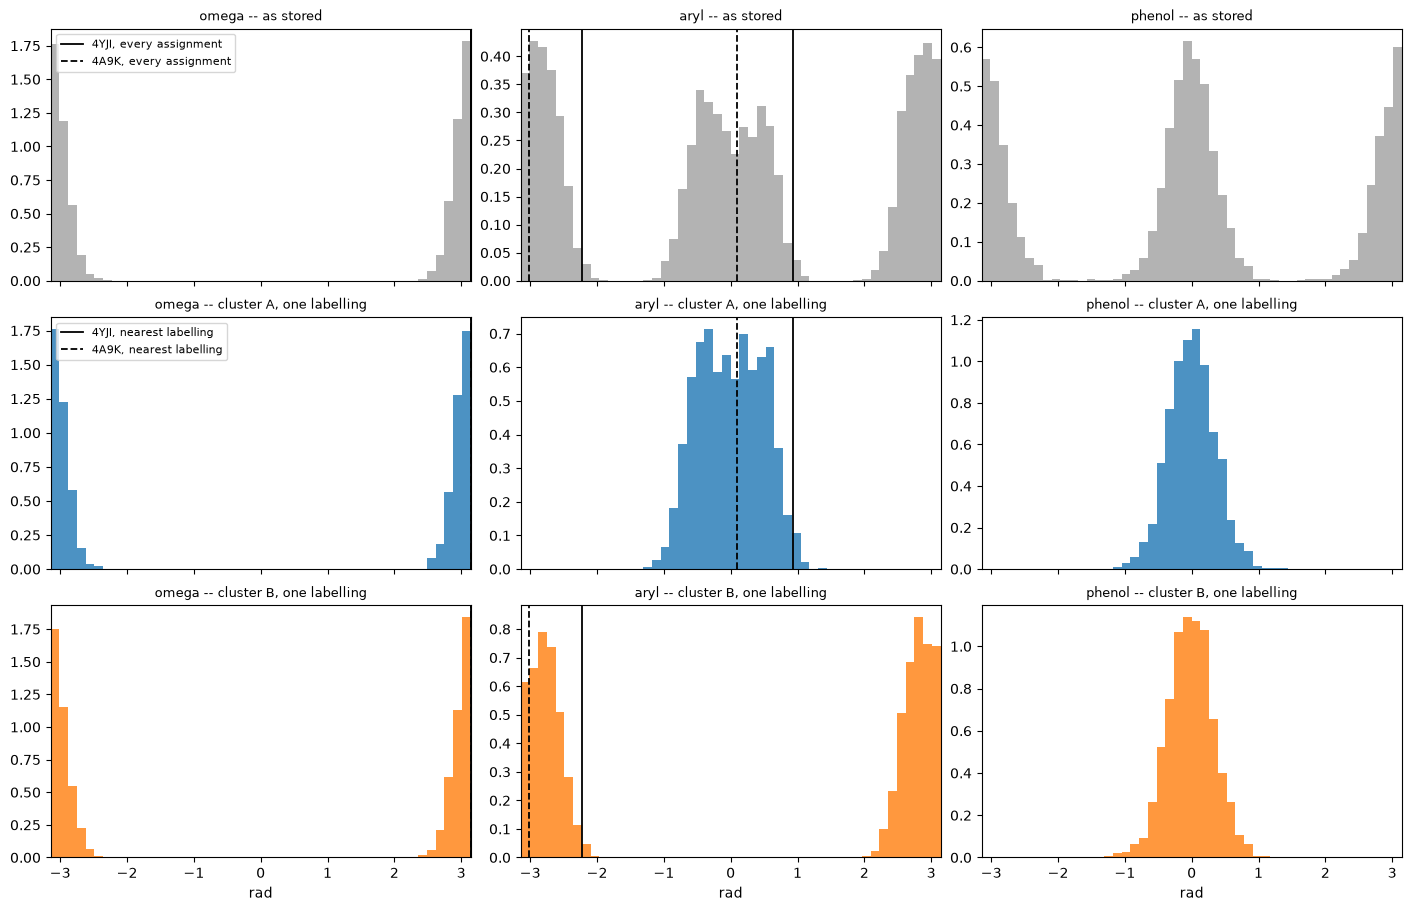

In [11]:
edges = np.linspace(-np.pi, np.pi, 49)
styles = {"4YJI": "-", "4A9K": "--"}
fig, axes = plt.subplots(1 + fit.n_clusters_, 3, figsize=(14, 3.0 * (1 + fit.n_clusters_)),
                         layout="constrained", sharex=True)
for t, name in enumerate(definitions.names):
    # top row: every frame as stored, so every assignment of the crystal is a legitimate place for it
    axes[0, t].hist(fit.closed_theta_[:, t], bins=edges, density=True, color="0.7")
    for pdb, r in rows.items():
        for k, v in enumerate(r[:, t]):
            if np.isfinite(v):
                for x in ((v, v - 2 * np.pi * np.sign(v)) if abs(v) > 3.0 else (v,)):   # a value at the seam shows at both ends
                    axes[0, t].axvline(x, color="k", ls=styles[pdb], lw=1.3,
                                       label=f"{pdb}, every assignment" if (t == 0 and k == 0) else None)
    axes[0, t].set_title(f"{name} -- as stored", fontsize=9)
    for c in range(fit.n_clusters_):
        ax = axes[1 + c, t]
        ax.hist(al["angles"][fit.labels_ == c, t], bins=edges, density=True, color=palette(c), alpha=0.8)
        for pdb, out in assigned.items():
            v = out["clusters"][c]["angles"][t]
            if np.isfinite(v):
                for x in ((v, v - 2 * np.pi * np.sign(v)) if abs(v) > 3.0 else (v,)):
                    ax.axvline(x, color="k", ls=styles[pdb], lw=1.3,
                               label=f"{pdb}, nearest labelling" if t == 0 else None)
        ax.set_title(f"{name} -- cluster {group_name(c)}, one labelling", fontsize=9)
    for ax in axes[:, t]:
        ax.set_xlim(-np.pi, np.pi)
for ax in (axes[0, 0], axes[1, 0]):
    handles, labels = ax.get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    ax.legend(unique.values(), unique.keys(), fontsize=8, loc="upper left")
for ax in axes[-1]:
    ax.set_xlabel("rad")
plt.show()

In the top row each crystal gives two lines in `aryl` half a turn apart, because the stored column
can be in either labelling. In each cluster row it gives one. `phenol` has no line: the crystal has
no hydrogen to measure it through.

**The crystals cannot be assigned to A or B.** On the columns a crystal can measure (`omega`, `aryl` and
its image) the density peaks of A and B coincide once the ring flip is applied: they differ only in the
`phenol` columns, which go through the hydroxyl hydrogen. `assign_reference` checks this and returns no
best cluster, only the clusters the structure is consistent with. The distances in the table are real,
but the nearer cluster is arbitrary. A crystal without hydrogens would need the hydroxyl placed
before it could say which of the two the conformation is.

## 9. Between the clusters: symmetry-corrected RMSD

The mean and standard deviation of the heavy-atom RMSD between every frame of one cluster and every
frame of another, after superposition and **minimised over the molecule's symmetry operations** (the
ring flip here). The diagonal is the spread inside a cluster, over distinct pairs. The second matrix is
the same pairs compared by atom index, which is what MDTraj or pytraj would report. Heavy atoms only,
by choice; the explanation is in
[Methods](../../../openmm_methods/analysis/clustering-and-symmetry.md#symmetry-corrected-rmsd).

In [12]:
from md_tools.analysis import enumerate_symmetry, heavy_atoms, operations_on_atoms, intercluster_rmsd

heavy = heavy_atoms(mol)
operations = operations_on_atoms(enumerate_symmetry(mol), heavy)
X = cmd.xyz[:, heavy, :] * 10.0                                    # nm -> A, heavy atoms in the molecule's order
corrected = intercluster_rmsd(X, fit.labels_, operations, max_per_cluster=None)
by_index = intercluster_rmsd(X, fit.labels_, operations[:1], max_per_cluster=None)
names_c = [group_name(c) for c in corrected["clusters"]]
def as_table(r):
    return pd.DataFrame([[f"{r['mean'][i, j]:.2f} +- {r['std'][i, j]:.2f}" for j in range(len(names_c))]
                         for i in range(len(names_c))], index=names_c, columns=names_c)
print(f"{len(heavy)} heavy atoms, {corrected['n_operations']} symmetry operations, frames per cluster {corrected['n_frames']}")
print("symmetry-corrected RMSD (A), mean +- std:"); display(as_table(corrected))
print("by atom index (no symmetry), mean +- std:"); display(as_table(by_index))

11 heavy atoms, 2 symmetry operations, frames per cluster {0: 2056, 1: 1935}
symmetry-corrected RMSD (A), mean +- std:


,A,B
A,0.32 +- 0.15,0.32 +- 0.15
B,0.32 +- 0.15,0.32 +- 0.15


by atom index (no symmetry), mean +- std:


,A,B
A,0.64 +- 0.35,0.64 +- 0.35
B,0.64 +- 0.35,0.64 +- 0.35


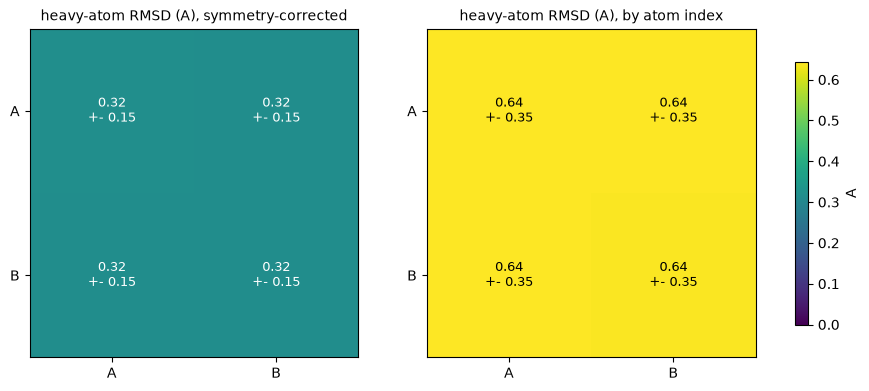

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), layout="constrained")
for ax, (title, r) in zip(axes, (("symmetry-corrected", corrected), ("by atom index", by_index))):
    im = ax.imshow(r["mean"], cmap="viridis", vmin=0, vmax=max(corrected["mean"].max(), by_index["mean"].max()))
    ax.set_xticks(range(len(names_c)), names_c); ax.set_yticks(range(len(names_c)), names_c)
    for i in range(len(names_c)):
        for j in range(len(names_c)):
            ax.text(j, i, f"{r['mean'][i, j]:.2f}\n+- {r['std'][i, j]:.2f}", ha="center", va="center",
                    color="w" if r["mean"][i, j] < 0.6 * im.get_clim()[1] else "k", fontsize=9)
    ax.set_title(f"heavy-atom RMSD (A), {title}", fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.8, label="A")
plt.show()

All four entries agree: A against B is as close as A against A. **Heavy-atom RMSD does not separate
the two clusters**, because they have the same heavy-atom conformations and differ in the hydroxyl
hydrogen, which the clustering sees through the `phenol` torsion and a heavy-atom RMSD does not.
By atom index the entries are about twice as large and equally undifferentiated: the ring flip alone
makes one conformer look different from itself.

## 10. A gauge on one torsion: `aryl` in a half-circle, `phenol` following

The ring flip is a **joint** symmetry here: it replaces `aryl` by `aryl + 180 deg` and `phenol` by
`phenol + 180 deg` **at once**. Folding each into a half-circle on its own would identify four
combinations where the flip identifies two, and merge real conformers. What is valid is to fix **one**
column and let the other follow: write each frame with `aryl` in a window **one half-turn wide, centred on the reference's own `aryl`**
(the density peak, so the cluster sits in the middle of the window and not astride its edge), using the
flip when that is what puts it there, and leave `phenol` on its full circle.

This is a choice for **drawing**, passed as `gauge=` to `align_all`. The clustering above is not touched:
its distance is the minimum over every operation and has no cut. The window does have one, half a turn from
the peak, so the notebook counts the frames near it. The explanation is in
[Methods](../../../openmm_methods/analysis/clustering-and-symmetry.md#a-gauge-on-one-column-for-a-symmetry-that-moves-several-columns).

In [14]:
gg = fit.align_all(per_cluster=True, gauge=("aryl", np.pi))        # a window of one half-turn, centred on the peak
_, lo, hi = gg["gauge_window"]
print(f"window: aryl in [{np.rad2deg(lo):.0f}, {np.rad2deg(hi):.0f}) deg, centred on the reference's "
      f"{np.rad2deg(fit.closed_theta_[ref, desc.names.index('aryl')]):.0f} deg")
ia, ip = desc.names.index("aryl"), desc.names.index("phenol")
ok = gg["gauge_satisfied"]
near = gg["gauge_edge_distance"] < 0.1
print(f"aryl in the window:     {ok.mean():.4f} of frames ({int((~ok).sum())} frames on the cut, in no window)")
print(f"within 0.1 rad of a cut: {near.mean():.4f} of frames")
shift_a = np.abs(wrap(gg["angles"][:, ia] - fit.closed_theta_[:, ia])) > 1.0
shift_p = np.abs(wrap(gg["angles"][:, ip] - fit.closed_theta_[:, ip])) > 1.0
print(f"frames the flip was applied to: {shift_a.mean():.3f}; aryl and phenol shifted together in "
      f"{(shift_a == shift_p)[ok].mean():.4f} of the satisfied frames")
rows = []
for c in range(fit.n_clusters_):
    m = fit.labels_ == c
    rows.append({"cluster": group_name(c), "frames": int(m.sum()),
                 "flip applied": round(float(shift_a[m].mean()), 3),
                 "not in window": int((~ok[m]).sum()),
                 "within 0.1 rad of a cut": round(float(near[m].mean()), 3)})
pd.DataFrame(rows)

window: aryl in [-106, 74) deg, centred on the reference's -16 deg
aryl in the window:     0.9998 of frames (1 frames on the cut, in no window)
within 0.1 rad of a cut: 0.0003 of frames
frames the flip was applied to: 0.556; aryl and phenol shifted together in 1.0000 of the satisfied frames


,cluster,frames,flip applied,not in window,within 0.1 rad of a cut
0,A,2056,0.546,1,0.0
1,B,1935,0.566,0,0.0


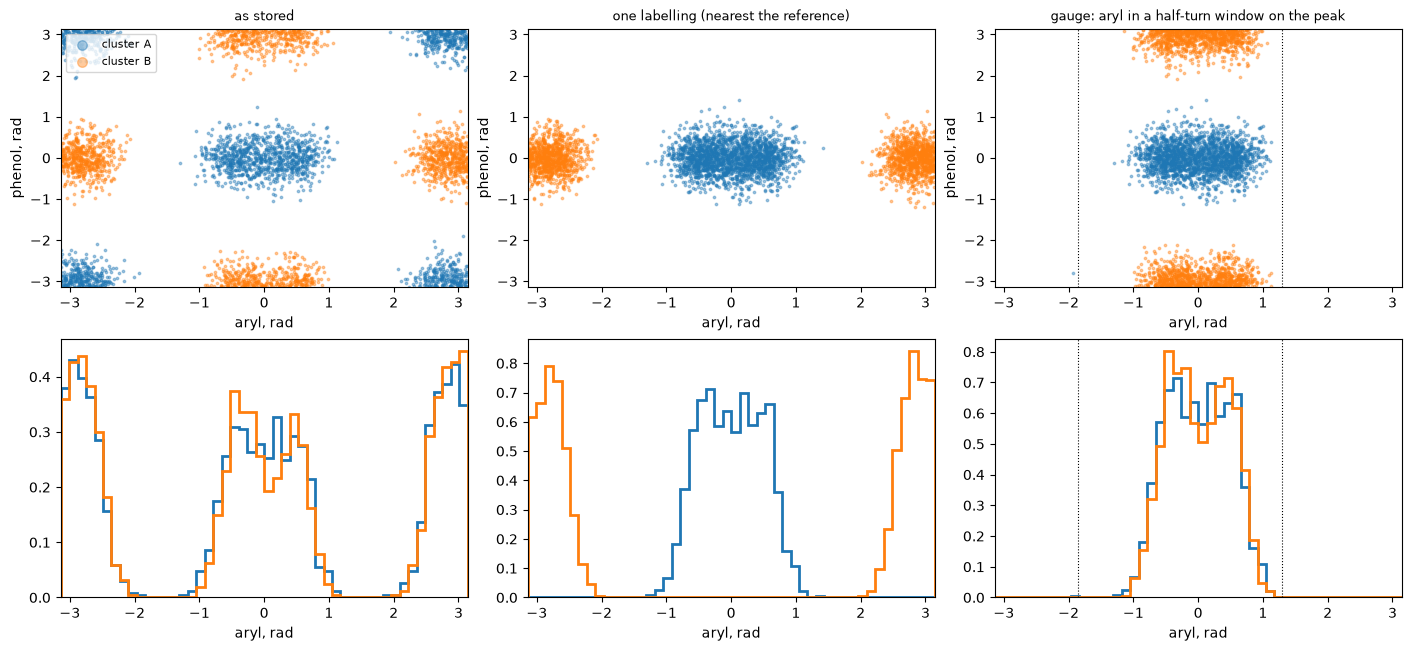

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6.4), layout="constrained")
versions = (("as stored", fit.closed_theta_), ("one labelling (nearest the reference)", al["angles"]),
            ("gauge: aryl in a half-turn window on the peak", gg["angles"]))
for col, (title, th) in enumerate(versions):
    for k in range(fit.n_clusters_):
        sel = fit.labels_ == k
        axes[0, col].scatter(th[sel, ia], th[sel, ip], s=3, alpha=0.4, color=palette(k),
                             label=f"cluster {group_name(k)}")
    axes[0, col].set_xlim(-np.pi, np.pi); axes[0, col].set_ylim(-np.pi, np.pi)
    axes[0, col].set_xlabel("aryl, rad"); axes[0, col].set_ylabel("phenol, rad")
    axes[0, col].set_title(title, fontsize=9)
    for k in range(fit.n_clusters_):
        axes[1, col].hist(th[fit.labels_ == k, ia], bins=edges, density=True, histtype="step", lw=2.0,
                          color=palette(k))
    axes[1, col].set_xlim(-np.pi, np.pi); axes[1, col].set_xlabel("aryl, rad")
for ax in axes[:, 2]:
    for edge_ in (lo, hi):
        ax.axvline(wrap(edge_), color="k", lw=0.8, ls=":")
axes[0, 0].legend(markerscale=4, fontsize=8)
plt.show()

Left: as stored, each cluster is drawn in two places on the torus. Middle: one labelling writes each
cluster once, but cluster B is where its own peak is, with `aryl` near 180 degrees, so the two clusters
look as if they differ in `aryl`. Right: the gauge, with the window centred on the peak. Both clusters
sit in the middle of it at `aryl` near the peak, and the distribution is one continuous bump with the
cut (dotted) in the empty gap. The difference between the clusters is where it belongs, in `phenol`:
A at 0 and B at 180 degrees, the hydroxyl hydrogen, which is also why the heavy-atom RMSD of section 9
cannot tell them apart. Where the flip was used, `aryl` and `phenol` both moved by half a turn, never
one of them alone. A window fixed at `[-90, 90)` instead would put the cut wherever zero happens to
fall, and a peak near it would be split; centring on the peak removes that choice. On this trajectory
the cut is in the gap: one frame in 3991 (0.03 %) is on it, outside the window, and the table above
flags it rather than moving it. That is a property of these data, and the count is how to check others.